# Fixed sample experiments

One fixed sample: Perron profiles, grid fineness, similarity-scale paths, and joint grid/scale limits. This follows the thesis subsection “Fixed sample experiments”.

Run the cells in order; all required functions are imported below. Every displayed figure is saved automatically under `outputs/pdfs/03_fixed_sample_experiments/`.

Source: [KDE chapter](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex).


In [ ]:
from _setup import setup_notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
from IPython.display import display
from experiments.joint_limits import run_experiment as grid_experiment
from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta, gaussian_mise_oracle_bandwidth
from kde_tools.density import exact_oracle_ise_values
from kde_tools.energy_minimization import EnergySearchConfig
from kde_tools.fourier.similarities import (
    DEFAULT_FREQUENCY_CUTOFF,
    DEFAULT_FREQUENCY_INTERVALS,
    beta2_divergence_matrix_fourier,
)
from kde_tools.joint_experiments import (
    local_beta2_log_metric,
    plot_selected_bandwidth_paths,
    run_custom_beta_paths,
    run_joint_limit_paths,
)
from kde_tools.perron import (
    doob_mass_from_perron,
    perron_eigenpair_from_divergence,
    perron_peak_index,
    perron_vector_from_divergence,
)
from kde_tools.qhat import minimize_qhat
from kde_tools.similarities import beta2_divergence_matrix
from scipy.optimize import minimize_scalar
from threadpoolctl import threadpool_limits

paths = setup_notebook("03_fixed_sample_experiments")
code_directory = paths.code
pdf_output_directory = paths.pdfs
seed = 20260818
kde_thesis_figure_dir = code_directory / "outputs/images/thesis"
kde_thesis_figure_dir.mkdir(parents=True, exist_ok=True)
ENERGY_SEARCH = EnergySearchConfig()
SEED = 20260823
N_DATA = 200
H_MIN, H_MAX = (0.01, 2.0)
BETA = 2.0
N_VALUES = np.arange(100, 3001, 100)
FREQUENCY_CUTOFF = DEFAULT_FREQUENCY_CUTOFF
FREQUENCY_INTERVALS = DEFAULT_FREQUENCY_INTERVALS
FFT_HALF_WIDTH = np.pi * FREQUENCY_INTERVALS / FREQUENCY_CUTOFF
FFT_SPATIAL_POINTS = 2 * FREQUENCY_INTERVALS
plt.style.use("default")
stationary_example_lambda_grid_N = 201


## 1. Example stationary distribution on a grid linear in $\psi_\beta$

Choose the sample size, number of bandwidth candidates, bandwidth interval, grid parameter $\beta$, and similarity scales below. The bandwidth candidates are uniformly spaced in $\psi_\beta(h)$. For $\beta=2$, this means uniform spacing in $\log h$, so the grid is geometric. The same fixed sample and grid are used for four Perron curves at $\lambda\in\{1,10,100,1000\}$. Dots show the Perron-vector components at the grid bandwidths. The red dashed line marks the Gaussian MISE-oracle bandwidth, and the dark gray dotted line marks the sample-specific continuous ISE minimum on the displayed bandwidth interval.


In [ ]:
stationary_example_seed = seed + 5
stationary_example_n = 200
stationary_example_N = 191
stationary_example_beta = 2.0
stationary_example_h_min = 0.01
stationary_example_h_max = 2.0
stationary_example_lambdas = np.array([1.0, 10.0, 100.0, 1000.0])
stationary_example_frequency_cutoff = DEFAULT_FREQUENCY_CUTOFF
stationary_example_frequency_intervals = DEFAULT_FREQUENCY_INTERVALS
stationary_example_half_width = (
    np.pi * stationary_example_frequency_intervals / stationary_example_frequency_cutoff
)
stationary_example_spatial_points = 2 * stationary_example_frequency_intervals
if stationary_example_n < 1:
    raise ValueError("stationary_example_n must be positive.")
if stationary_example_N < 2:
    raise ValueError("stationary_example_N must be at least two.")
if not 0.0 < stationary_example_h_min < stationary_example_h_max:
    raise ValueError("Require 0 < h_min < h_max.")
if np.any(stationary_example_lambdas <= 0.0):
    raise ValueError("stationary_example_lambdas must be positive.")
if stationary_example_half_width <= 0.0:
    raise ValueError("stationary_example_half_width must be positive.")
if stationary_example_spatial_points < 2 or stationary_example_spatial_points % 2:
    raise ValueError("stationary_example_spatial_points must be a positive even integer.")
stationary_example_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=stationary_example_h_min,
    h_max=stationary_example_h_max,
    beta=stationary_example_beta,
    grid_size=stationary_example_N,
)
stationary_example_rng = np.random.default_rng(stationary_example_seed)
stationary_example_samples = stationary_example_rng.normal(size=stationary_example_n)
stationary_example_divergence = beta2_divergence_matrix_fourier(
    samples=stationary_example_samples,
    h_grid=stationary_example_grid,
    half_width=stationary_example_half_width,
    spatial_points=stationary_example_spatial_points,
)
stationary_example_similarities = {}
stationary_example_perron_vectors = {}
stationary_example_spectral_gaps = {}
stationary_example_peak_indices = {}
stationary_example_peak_bandwidths = {}
for current_lambda in stationary_example_lambdas:
    current_similarity = np.exp(-current_lambda * stationary_example_divergence)
    np.fill_diagonal(current_similarity, 1.0)
    current_perron_result = perron_eigenpair_from_divergence(
        stationary_example_divergence, current_lambda
    )
    current_perron = current_perron_result.vector
    current_peak_index = int(perron_peak_index(current_perron))
    stationary_example_similarities[current_lambda] = current_similarity
    stationary_example_perron_vectors[current_lambda] = current_perron
    stationary_example_spectral_gaps[current_lambda] = float(
        np.exp(-current_lambda * current_perron_result.minimum_divergence)
        * current_perron_result.spectral_gap
        / (
            1.0
            + np.exp(-current_lambda * current_perron_result.minimum_divergence)
            * current_perron_result.eigenvalue
        )
    )
    stationary_example_peak_indices[current_lambda] = current_peak_index
    stationary_example_peak_bandwidths[current_lambda] = float(
        stationary_example_grid[current_peak_index]
    )
stationary_example_reference_lambda = float(stationary_example_lambdas[0])
stationary_example_similarity = stationary_example_similarities[stationary_example_reference_lambda]
stationary_example_perron = stationary_example_perron_vectors[stationary_example_reference_lambda]
stationary_example_mass = doob_mass_from_perron(stationary_example_perron)
stationary_example_peak_index = stationary_example_peak_indices[stationary_example_reference_lambda]
stationary_example_peak_h = stationary_example_peak_bandwidths[stationary_example_reference_lambda]
stationary_example_spectral_gap = stationary_example_spectral_gaps[
    stationary_example_reference_lambda
]
stationary_example_oracle_h = gaussian_mise_oracle_bandwidth(stationary_example_n)
# Find continuous local minima on the displayed interval, then compare them
# with its endpoints. The scan brackets candidates; it does not select a grid point.
def stationary_example_ise(h):
    return float(exact_oracle_ise_values(
        samples=stationary_example_samples, h_grid=np.array([h]), sigma2=1.0
    )[0])

stationary_example_ise_scan = np.geomspace(stationary_example_h_min, stationary_example_h_max, 257)
stationary_example_ise_scan_values = exact_oracle_ise_values(
    samples=stationary_example_samples, h_grid=stationary_example_ise_scan, sigma2=1.0
)
stationary_example_ise_candidates = [
    (stationary_example_ise_scan_values[0], stationary_example_h_min),
    (stationary_example_ise_scan_values[-1], stationary_example_h_max),
]
for i in range(1, len(stationary_example_ise_scan) - 1):
    if (stationary_example_ise_scan_values[i] <= stationary_example_ise_scan_values[i - 1]
            and stationary_example_ise_scan_values[i] <= stationary_example_ise_scan_values[i + 1]):
        result = minimize_scalar(
            stationary_example_ise,
            bounds=(stationary_example_ise_scan[i - 1], stationary_example_ise_scan[i + 1]),
            method="bounded",
            options={"xatol": 1e-12},
        )
        if not result.success:
            raise RuntimeError("Continuous ISE minimization failed.")
        stationary_example_ise_candidates.append((float(result.fun), float(result.x)))
_, stationary_example_ise_h = min(stationary_example_ise_candidates)
stationary_example_target_roughness = 3.0 / (8.0 * np.sqrt(np.pi))
stationary_example_h_speed = (
    3.0 / (32.0 * np.sqrt(np.pi) * stationary_example_n * stationary_example_target_roughness)
) ** (1.0 / 5.0)
stationary_example_log_h_min = np.log10(stationary_example_h_min)
stationary_example_log_h_max = np.log10(stationary_example_h_max)
stationary_example_log_h_span = stationary_example_log_h_max - stationary_example_log_h_min
stationary_example_h_speed_paper_x = (
    np.log10(stationary_example_h_speed) - stationary_example_log_h_min
) / stationary_example_log_h_span
stationary_example_h_speed_index = stationary_example_h_speed_paper_x * (stationary_example_N - 1)
fig, ax = plt.subplots(figsize=(10.5, 5.5))
stationary_example_curve_colors = ("#E69F00", "#009E73", "#D55E00", "#222222")
stationary_example_profile_colors = ("#79ABA3", "#43877E", "#28685F", "#153E3B")
if len(stationary_example_profile_colors) != len(stationary_example_lambdas):
    raise ValueError("Provide one curve colour per lambda value.")
for current_lambda, current_color in zip(
    stationary_example_lambdas, stationary_example_profile_colors
):
    current_perron = stationary_example_perron_vectors[current_lambda]
    ax.plot(
        stationary_example_grid,
        current_perron,
        color=current_color,
        linewidth=2.0,
        marker="o",
        markersize=3.5,
        label=f"$\\lambda={current_lambda:g}$",
    )
ax.set_xscale("log")
ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2],
              labels=["0.01", "0.02", "0.05", "0.1", "0.2", "0.5", "1", "2"])
ax.set_xlabel("bandwidth $h_i$")
ax.set_ylabel("Perron-vector component $v_i$")
ax.grid(alpha=0.3)
ax.axvline(
    stationary_example_oracle_h,
    color="tab:red",
    linestyle="--",
    label=rf"$h_{{\mathrm{{oracle}}}}={stationary_example_oracle_h:.4f}$",
)
ax.axvline(
    stationary_example_ise_h,
    color="#555555",
    linestyle=":",
    label=rf"$\hat{{h}}_0={stationary_example_ise_h:.4f}$",
)
ax.legend(ncol=2, fontsize=8.5)
plt.tight_layout()
fig.savefig(kde_thesis_figure_dir / "stationary_distribution_plot_001.pdf", dpi=100)
plt.show()


### Grid-fineness sensitivity across similarity scales

This experiment reuses the same fixed sample and bandwidth interval while varying the number $N=11,16,\ldots,1001$ of bandwidth candidates linear in $\psi_\beta$. It plots $N$ against the bandwidth selected by the Perron-vector maximum for $\lambda\in\{1,10,100,1000\}$. Envelope fits are omitted so that the four grid-stability trajectories remain directly comparable. A thin grey vertical line at $N=201$ identifies the grid size used in Figure 3.3.


completed 20/199 grid sizes
completed 40/199 grid sizes
completed 60/199 grid sizes
completed 80/199 grid sizes
completed 100/199 grid sizes
completed 120/199 grid sizes
completed 140/199 grid sizes
completed 160/199 grid sizes
completed 180/199 grid sizes
completed 199/199 grid sizes
Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_scale_selection_kde/003_matplotlib_figure.pdf


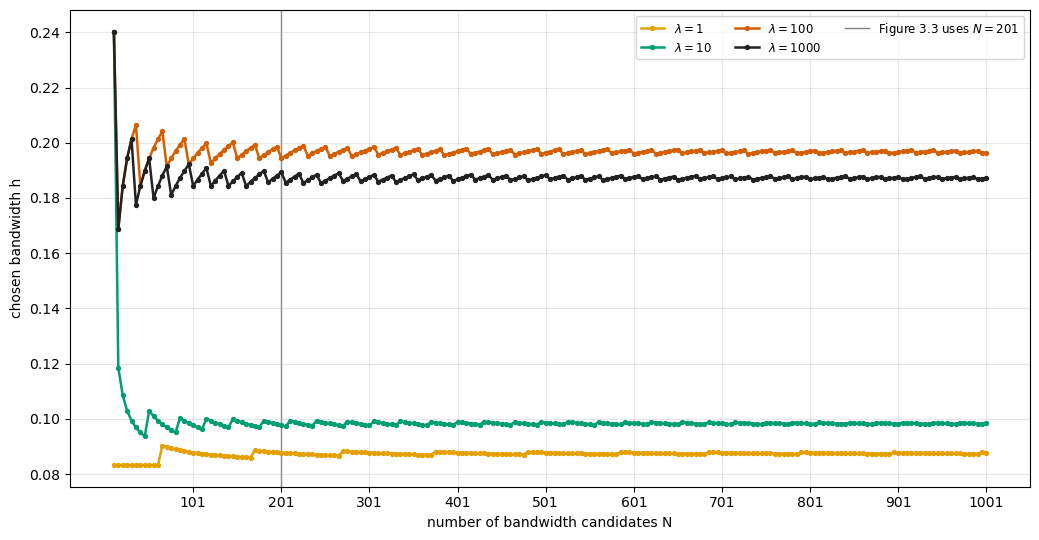

In [ ]:
stationary_example_grid_fineness_lambdas = stationary_example_lambdas.copy()
stationary_example_grid_fineness_N_values = np.arange(11, 1002, 5, dtype=int)
stationary_example_grid_fineness_tick_values = np.arange(101, 1002, 100, dtype=int)
stationary_example_grid_fineness_selected_indices = np.empty(
    (len(stationary_example_grid_fineness_lambdas), len(stationary_example_grid_fineness_N_values)),
    dtype=int,
)
stationary_example_grid_fineness_selected_bandwidths = np.empty(
    stationary_example_grid_fineness_selected_indices.shape, dtype=float
)
for position, current_N in enumerate(stationary_example_grid_fineness_N_values):
    current_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=stationary_example_h_min,
        h_max=stationary_example_h_max,
        beta=stationary_example_beta,
        grid_size=int(current_N),
    )
    current_divergence = beta2_divergence_matrix_fourier(
        samples=stationary_example_samples,
        h_grid=current_grid,
        half_width=stationary_example_half_width,
        spatial_points=stationary_example_spatial_points,
    )
    for lambda_position, current_lambda in enumerate(stationary_example_grid_fineness_lambdas):
        current_perron = perron_vector_from_divergence(current_divergence, current_lambda)
        current_stationary_mass = doob_mass_from_perron(current_perron)
        current_selected_index = int(perron_peak_index(current_perron))
        stationary_example_grid_fineness_selected_indices[lambda_position, position] = (
            current_selected_index
        )
        stationary_example_grid_fineness_selected_bandwidths[lambda_position, position] = (
            current_grid[current_selected_index]
        )
    if (position + 1) % 20 == 0 or position + 1 == len(stationary_example_grid_fineness_N_values):
        print(
            f"completed {position + 1}/{len(stationary_example_grid_fineness_N_values)} grid sizes"
        )
fig, ax = plt.subplots(figsize=(10.5, 5.5))
for lambda_position, (current_lambda, current_color) in enumerate(
    zip(stationary_example_grid_fineness_lambdas, stationary_example_curve_colors)
):
    ax.plot(
        stationary_example_grid_fineness_N_values,
        stationary_example_grid_fineness_selected_bandwidths[lambda_position],
        color=current_color,
        linewidth=1.8,
        marker="o",
        markersize=2.8,
        label=f"$\\lambda={current_lambda:g}$",
    )
ax.set_xlabel("number of bandwidth candidates N")
ax.set_ylabel("chosen bandwidth h")
ax.set_xticks(stationary_example_grid_fineness_tick_values)
ax.grid(alpha=0.3)
ax.axvline(
    stationary_example_lambda_grid_N,
    color="#7f7f7f",
    linewidth=1.0,
    label=f"Figure 3.3 uses $N={stationary_example_lambda_grid_N}$",
    zorder=0,
)
ax.legend(ncol=3, fontsize=8.5)
plt.tight_layout()
fig.savefig(kde_thesis_figure_dir / "grid_fineness_chosen_bandwidths.pdf", dpi=100)
plt.show()


### Similarity scale versus chosen bandwidth

For the same fixed sample as Figure 3.1, the plot below uses $N=201$ bandwidths linear in $\psi_\beta$, varies the similarity scale $\lambda$ in $S_{ij}=\exp(-\lambda D_{2,ij})$, and records the bandwidth at the maximum of the Doob stationary mass. The blue dashed horizontal line marks the Gaussian MISE-oracle bandwidth, and the purple dashed horizontal line marks the sample-specific continuous ISE minimum on the displayed bandwidth interval.

The two red dashed horizontal lines mark the bandwidths in the closest adjacent pair on this grid, found by minimizing the adjacent beta-2 divergences.


In [ ]:
stationary_example_lambda_values = np.geomspace(0.01, 10000.0, 101)
stationary_example_lambda_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=stationary_example_h_min,
    h_max=stationary_example_h_max,
    beta=stationary_example_beta,
    grid_size=stationary_example_lambda_grid_N,
)
stationary_example_log_lambda_min = np.log10(stationary_example_lambda_values[0])
stationary_example_log_lambda_max = np.log10(stationary_example_lambda_values[-1])
stationary_example_lambda_divergence = beta2_divergence_matrix_fourier(
    samples=stationary_example_samples,
    h_grid=stationary_example_lambda_grid,
    half_width=stationary_example_half_width,
    spatial_points=stationary_example_spatial_points,
)
stationary_example_lambda_closest_pair_left_index = int(
    np.argmin(np.diag(stationary_example_lambda_divergence, k=1))
)
stationary_example_lambda_closest_pair_indices = (
    stationary_example_lambda_closest_pair_left_index,
    stationary_example_lambda_closest_pair_left_index + 1,
)
stationary_example_lambda_closest_pair_bandwidths = stationary_example_lambda_grid[
    list(stationary_example_lambda_closest_pair_indices)
]
stationary_example_lambda_selected_indices = np.empty(
    len(stationary_example_lambda_values), dtype=int
)
for index, current_lambda in enumerate(stationary_example_lambda_values):
    current_perron = perron_vector_from_divergence(
        stationary_example_lambda_divergence, current_lambda
    )
    current_mass = doob_mass_from_perron(current_perron)
    stationary_example_lambda_selected_indices[index] = int(perron_peak_index(current_perron))
stationary_example_lambda_selected_bandwidths = stationary_example_lambda_grid[
    stationary_example_lambda_selected_indices
]
fig, ax = plt.subplots(figsize=(10.5, 5.5))
ax.step(
    stationary_example_lambda_values,
    stationary_example_lambda_selected_bandwidths,
    where="post",
    color="#222222",
    linewidth=2.0,
    marker="o",
    markersize=3.5,
    label=f"spectral selection ($N={stationary_example_lambda_grid_N}$)",
)
ax.axhline(
    stationary_example_oracle_h,
    color="tab:blue",
    linestyle="--",
    linewidth=1.8,
    label=f"Gaussian MISE oracle: h={stationary_example_oracle_h:.4g}",
)
ax.axhline(
    stationary_example_ise_h,
    color="tab:purple",
    linestyle="--",
    linewidth=1.8,
    label=f"sample ISE minimum: h={stationary_example_ise_h:.4g}",
)
for grid_index, bandwidth in zip(
    stationary_example_lambda_closest_pair_indices,
    stationary_example_lambda_closest_pair_bandwidths,
):
    ax.axhline(
        bandwidth,
        color="tab:red",
        linestyle="--",
        linewidth=0.9,
        zorder=1.8,
        label=f"closest pair: $h_{{{grid_index + 1}}}={bandwidth:.6f}$",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(stationary_example_lambda_values[0], stationary_example_lambda_values[-1])
ax.set_ylim(stationary_example_h_min, stationary_example_h_max)
ax.set_xlabel("similarity scale $\\lambda$")
ax.set_ylabel("chosen bandwidth h")
ax.grid(alpha=0.3)
ax.legend(fontsize=8.5)
plt.tight_layout()
fig.savefig(kde_thesis_figure_dir / "chosen_bandwidth_vs_lambda_M1_fixed_sample.pdf", dpi=100)
plt.show()


## Joint grid/scale limits on the fixed sample

This section isolates the spectral asymptotics from the separate sample-size limit. It fixes the data sample size, the underlying distribution, and the bandwidth interval, while varying only the bandwidth-grid size $N$ and the similarity localization $\lambda_N$.

One sample from $N(0,1)$ is drawn once and held fixed throughout. Every $(N,\lambda_N)$ configuration is evaluated on this same sample, so this section isolates the grid and localization limits from sample-to-sample variation.

We study the regimes $\lambda_N=N^\alpha$, where $\alpha\in\{0,1/2,1,3/2,2,3\}$.


L² inner products use direct frequency quadrature (`frequency_trapezoid_v1`) with the shared production settings **Omega = 450 and K = 1376 intervals (1377 nodes)**. The compatibility values `half_width = pi*K/Omega` and `spatial_points = 2*K` specify this frequency grid; the L² helper does not reconstruct spatial densities. Configuration identities include the frequency grid, so checkpoints from other grids are not reused. Rerun setup after updating the helpers.



In [ ]:
plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(SEED)
samples = rng.normal(loc=0.0, scale=1.0, size=N_DATA)
endpoint_check = pd.DataFrame(
    {
        "N": N_VALUES,
        "first h": [
            bandwidth_grid_linear_in_psi_beta(H_MIN, H_MAX, BETA, int(N))[0] for N in N_VALUES
        ],
        "last h": [
            bandwidth_grid_linear_in_psi_beta(H_MIN, H_MAX, BETA, int(N))[-1] for N in N_VALUES
        ],
        "Delta log(h)": [np.log(H_MAX / H_MIN) / (N - 1) for N in N_VALUES],
    }
)
sample_summary = pd.DataFrame({"mean": [samples.mean()], "sd": [samples.std(ddof=1)]})
print(f"Generated one sample with n={N_DATA}, using seed={SEED}.")
display(sample_summary.round(6))
display(endpoint_check)


## Continuous large-$N$, large-$\lambda$ prediction

Write $\psi=\log h$. Locally, beta-2 divergence has the quadratic expansion

$$D_2(\widehat f_h,\widehat f_{he^\delta})
=a(h)\delta^2+o(\delta^2),\qquad
a(h)=\frac12\left\|\partial_\psi\widehat f_h\right\|_2^2.$$

The localized continuous kernel has row width proportional to $a(h)^{-1/2}$, so its Perron mass concentrates at

$$h_\infty=\operatorname*{arg\,min}_{h\in[0.01,2]}a(h).$$

For Gaussian KDEs, this coefficient can be evaluated without numerical differentiation. If $d_{rs}=(X_r-X_s)^2$, $q=2h^2$, and $g_q(d)=(2\pi q)^{-1/2}e^{-d/(2q)}$, then

$$a(h)=2h^4\frac1{n^2}\sum_{r,s}g_q(d_{rs})
\left(\frac{3}{4q^2}-\frac{3d_{rs}}{2q^3}
+\frac{d_{rs}^2}{4q^4}\right).$$

In [ ]:
squared_differences = (samples[:, None] - samples[None, :]) ** 2
continuous_minimum = minimize_qhat(samples, H_MIN, H_MAX, r=0.0, config=ENERGY_SEARCH)
if continuous_minimum["diagnostics"]["resolution_stable"] is False:
    raise ArithmeticError("Energy search did not stabilize; increase ENERGY_SEARCH resolution.")
h_infinity = continuous_minimum["global_minimum"]["h"]
metric_grid = np.geomspace(H_MIN, H_MAX, 600)
metric_values = np.array([local_beta2_log_metric(h, squared_differences) for h in metric_grid])
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(metric_grid, metric_values, color="#244c66", linewidth=2.2)
ax.axvline(
    h_infinity,
    color="#c23b22",
    linestyle="--",
    label=f"continuous prediction $h_\\infty={h_infinity:.4f}$",
)
ax.set(
    xscale="log",
    xlabel="bandwidth $h$",
    ylabel="local coefficient $a(h)$",
    title=f"Continuous localized-kernel criterion on $[{H_MIN:g},{H_MAX:g}]$",
)
ax.legend()
plt.show()
print(f"Continuous-limit prediction: h_infinity = {h_infinity:.8f}")


## Numerical method and validation

The project already contains an exact analytic beta-2 calculation. Its cost grows like $N^2n^2$, so the full sweep uses the existing Fourier reconstruction and one matrix product per $N$. The next cell checks that approximation against the exact helper on the smallest grid.

For numerical stability, the Perron vector is computed from the off-diagonal part $A_N=S_N-I_N$. Adding the identity does not change the eigenvectors. Before the centralized `eigh` solve, all off-diagonal entries are multiplied by the same factor so that the largest equals one; this also leaves the eigenvectors unchanged and prevents the $\alpha=3$ regime from becoming numerically indistinguishable from the identity.

In [ ]:
validation_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN, h_max=H_MAX, beta=BETA, grid_size=25
)
validation_exact = beta2_divergence_matrix(samples, validation_grid)
validation_fft = beta2_divergence_matrix_fourier(
    samples, validation_grid, half_width=FFT_HALF_WIDTH, spatial_points=FFT_SPATIAL_POINTS
)
validation_abs_error = np.max(np.abs(validation_fft - validation_exact))
validation_rel_error = validation_abs_error / np.max(validation_exact)
print(f"maximum absolute D2 error: {validation_abs_error:.3e}")
print(f"error relative to max(D2): {validation_rel_error:.3e}")
if validation_rel_error > 2e-05:
    warnings.warn(
        "Increase FREQUENCY_INTERVALS to refine the frequency grid, or FREQUENCY_CUTOFF to reduce truncation."
    )


In [ ]:
LAMBDA_RULES = {
    "$N^{1/2}$ (admissible)": lambda N: N**0.5,
    "$N$ (admissible)": lambda N: float(N),
    "$N^{3/2}$ (admissible)": lambda N: N**1.5,
    "$1$ (not localized)": lambda N: 1.0,
    "$N^2$ (mesh-scale)": lambda N: float(N**2),
    "$N^3$ (collapse)": lambda N: float(N**3),
}
REGIME_ORDER = list(LAMBDA_RULES)
REGIME_COLORS = dict(
    zip(REGIME_ORDER, ["#0072B2", "#009E73", "#CC79A7", "#E69F00", "#7A7A7A", "#D55E00"])
)
results, largest_grid_vectors, elapsed = run_joint_limit_paths(
    beta=BETA,
    half_width=FFT_HALF_WIDTH,
    spatial_points=FFT_SPATIAL_POINTS,
    h_max=H_MAX,
    h_min=H_MIN,
    lambda_rules=LAMBDA_RULES,
    grid_sizes=N_VALUES,
    regime_order=REGIME_ORDER,
    h_reference=h_infinity,
    samples=samples,
)


In [ ]:
plot_ticks = np.array([100, 500, 1000, 1500, 2000, 2500, 3000])


In [ ]:
plot_selected_bandwidth_paths(
    show_continuous_reference=False,
    h_max=H_MAX,
    h_min=H_MIN,
    regime_colors=REGIME_COLORS,
    regime_order=REGIME_ORDER,
    h_infinity=h_infinity,
    metric_grid=metric_grid,
    metric_values=metric_values,
    plot_ticks=plot_ticks,
    results=results,
    squared_differences=squared_differences,
)


In [ ]:
plot_selected_bandwidth_paths(
    show_continuous_reference=True,
    h_max=H_MAX,
    h_min=H_MIN,
    regime_colors=REGIME_COLORS,
    regime_order=REGIME_ORDER,
    h_infinity=h_infinity,
    metric_grid=metric_grid,
    metric_values=metric_values,
    plot_ticks=plot_ticks,
    results=results,
    squared_differences=squared_differences,
    output_path=code_directory
    / "outputs/pdfs/experiment_1_joint_n_lambda_limit/003_finite_selector_versus_continuous_reference.pdf",
)


In [ ]:
CUSTOM_ALPHA_VALUES = np.round(np.arange(1.0, 3.0 + 0.05, 0.5), 1)
CUSTOM_ALPHA_VALUES


## Interpretation

- The three admissible sequences approach the same sample-conditional continuous reference, although $N^{1/2}$ localizes more slowly than $N$ and $N^{3/2}$.
- With $\lambda_N=1$, the kernel never becomes globally localized. Its selector can stabilize, but not at the large-$\lambda$ criterion.
- With $\lambda_N=N^2$, the neighbor exponent remains at mesh scale instead of tending to zero. The selected bandwidth may look plausible, but it is a discretized-kernel limit rather than the target continuous local limit.
- With $\lambda_N=N^3$, neighboring similarities collapse toward zero and the matrix approaches the identity. The Perron eigenvalue becomes nearly degenerate, so an apparently accurate argmax is not evidence of the desired limit.

This is why the mesh diagnostic and final table are retained in [06_additional_experiments.ipynb](06_additional_experiments.ipynb): the bandwidth path alone cannot verify the joint-limit assumptions.

## Scope and reproducibility

Change SEED or N_DATA only for a robustness rerun; keep them fixed within a run. The joint-limit sweep intentionally makes no claim about $n\to\infty$. The follow-up experiment in [04_repeated_sampling_experiments.ipynb](04_repeated_sampling_experiments.ipynb) keeps $n$ fixed and freezes the numerically calibrated pair $(N,\lambda)=(1000,1000)$ while varying only the sample.

## Joint $(N,\lambda_N)$ limit for a user-selected $\beta$

This repeats Figure 3.6 with a freely chosen value of $\beta$. Here $\beta$ determines the coordinate $\psi_\beta$ in which the bandwidth grid is equidistant, and hence the local criterion $\widehat Q_{n,\beta}(h)=h^\beta\lVert\partial_h\widehat f_h\rVert_2^2$. The similarity still uses the same $L^2$ divergence as the original experiment. Change only `CUSTOM_BETA` in the first line of the next cell.

In [ ]:
CUSTOM_BETA = 1 / 7
if not np.isfinite(CUSTOM_BETA) or CUSTOM_BETA <= 0.0:
    raise ValueError("CUSTOM_BETA must be positive and finite.")
CUSTOM_BETA_N_VALUES = N_VALUES.copy()
CUSTOM_ALPHA_VALUES = np.round(np.arange(1.0, 3.0 + 0.05, 0.5), 1)
CUSTOM_BETA_LAMBDA_RULES = {"$N^{0.5}$": lambda N: N**0.5}
for alpha in CUSTOM_ALPHA_VALUES:
    if np.isclose(alpha, 2.0):
        label = "$N^{2.0}$ (mesh-scale)"
    elif alpha > 2.0:
        label = f"$N^{{{alpha:.1f}}}$ (collapse)"
    else:
        label = f"$N^{{{alpha:.1f}}}$"
    CUSTOM_BETA_LAMBDA_RULES[label] = lambda N, alpha=alpha: N**alpha
CUSTOM_BETA_LAMBDA_RULES["$1$ (not localized)"] = lambda N: 1.0
CUSTOM_BETA_REGIME_ORDER = list(CUSTOM_BETA_LAMBDA_RULES)
cmap = plt.colormaps["turbo"]
CUSTOM_BETA_REGIME_COLORS = {
    regime: cmap(i / (len(CUSTOM_BETA_REGIME_ORDER) - 1))
    for i, regime in enumerate(CUSTOM_BETA_REGIME_ORDER)
}
custom_beta_results, custom_beta_h_infinity = run_custom_beta_paths(
    beta=CUSTOM_BETA,
    lambda_rules=CUSTOM_BETA_LAMBDA_RULES,
    grid_sizes=CUSTOM_BETA_N_VALUES,
    regime_order=CUSTOM_BETA_REGIME_ORDER,
    search=ENERGY_SEARCH,
    half_width=FFT_HALF_WIDTH,
    spatial_points=FFT_SPATIAL_POINTS,
    h_max=H_MAX,
    h_min=H_MIN,
    samples=samples,
    squared_differences=squared_differences,
)


In [ ]:
custom_beta_plot_ticks = np.array([100, 500, 1000, 1500, 2000, 2500, 3000])
fig, ax = plt.subplots(figsize=(9.5, 5.8))
for regime in CUSTOM_BETA_REGIME_ORDER:
    subset = custom_beta_results[custom_beta_results["regime"] == regime]
    admissible = "admissible" in regime
    ax.plot(
        subset["N"],
        subset["selected_h"],
        marker="o",
        linewidth=2.2 if admissible else 1.6,
        linestyle="-" if admissible else "--",
        color=CUSTOM_BETA_REGIME_COLORS[regime],
        label=regime,
    )
ax.axhline(
    custom_beta_h_infinity,
    color="black",
    linestyle=":",
    linewidth=2.2,
    label=f"continuous $h_\\infty={custom_beta_h_infinity:.4f}$",
)
ax.set(
    xlabel="number of bandwidths $N$",
    ylabel="selected bandwidth $h_{\\mathrm{spec},N}$",
    title=f"Joint grid-localization limit for $\\beta={CUSTOM_BETA:g}$",
)
ax.set_xticks(custom_beta_plot_ticks, labels=custom_beta_plot_ticks)
ax.legend(ncol=2, frameon=True)
fig.tight_layout()
plt.show()


## Additional grid parameters: r=1 and r=13/14


## Figure 3.6 grid experiments: $r=1$ and $r=13/14$

Choose `GRID_R = "1"` or `"13/14"` in the setup cell, then run all cells in order.
The same runner calculates both grids and keeps their results separate. The
filename is retained for existing links.

The fixed sample, interval, grid sizes, lambda regimes, and numerical checks are
shared. Both grid definitions are retained below.

Sources: [thesis grid definition, Eq. `eq:def_r_linear`](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex),
[original experiment](experiment_1_joint_N_lambda_limit.ipynb), and
[shared runner](../experiments/joint_limits/run_experiment.py).


## Setup and grid choice

Choose `GRID_R` below. Data and image names remain specific to that grid; automatic PDFs go to `outputs/pdfs/03_fixed_sample_experiments/`.


In [ ]:
GRID_R = "1"
experiment_name = grid_experiment.configure_grid(GRID_R)
pdf_directory = pdf_output_directory


## Run and validate the selected grid

The runner compares both endpoints and all detected interior minima of the
matching $\widehat Q_r$ criterion on $[0.01,2]$. It retains the exact-Gaussian
cross-check, doubled frequency-resolution check, and eigenpair diagnostics.
Numerical settings are recorded with each experiment's checkpoints.

Sources: [thesis Proposition `prop:main_thm`](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex)
and [runner and validation](../experiments/joint_limits/run_experiment.py).


In [ ]:
with threadpool_limits(limits=2):
    results, reference, metric_h, metric_q = grid_experiment.run_experiment()
print("Continuous reference on [0.01, 2]:", reference)
display(results.pivot(index="N", columns="alpha", values="selected_h"))


In [ ]:
image_path = grid_experiment.plot_results(results, reference)
print("PNG:", image_path)
print("Automatic PDFs:", pdf_directory)


## Grid definition: r=1

Repeat the current Figure 3.6 fixed-sample joint $(N,\lambda_N)$ experiment, changing only the bandwidth grid to

$$h_i=0.01+\frac{i-1}{N-1}(2-0.01),\qquad i=1,\ldots,N.$$

The sample is the same 200 standard-normal draws from NumPy's `default_rng(20260823)`. The interval remains $[0.01,2]$, $N=100,200,\ldots,3000$, and $\lambda_N\in\{1,N^{1/2},N,N^{3/2},N^2,N^3\}$. The grid helper calls this `beta=0`, corresponding to thesis $r=1$ through $\beta=2(1-r)$; the divergence remains one half of the squared $L^2$ distance.

Sources: [current Figure 3.6 and grid definition, Eq. `eq:def_r_linear`](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex); [original experiment, initial setup and sweep](experiment_1_joint_N_lambda_limit.ipynb); [grid helper](../kde_tools/bandwidths.py).

## Grid definition: r=13/14

Repeat the fixed-sample joint $(N,\lambda_N)$ experiment with

$$h_i=\left[0.01^{13/14}+\frac{i-1}{N-1}\left(2^{13/14}-0.01^{13/14}\right)\right]^{14/13}.$$

The sample and all other settings match the preceding linear-grid run: 200 standard-normal draws from `default_rng(20260823)`, bandwidth interval $[0.01,2]$, $N=100,200,\ldots,3000$, and $\lambda_N\in\{1,N^{1/2},N,N^{3/2},N^2,N^3\}$. The grid helper uses $\beta=2(1-r)=1/7$; the divergence remains one half of the squared $L^2$ distance.

Sources: [thesis grid definition, Eq. `eq:def_r_linear`](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex); [original Figure 3.6 workflow](experiment_1_joint_N_lambda_limit.ipynb); [grid helper](../kde_tools/bandwidths.py); [grid choice above](#setup-and-grid-choice).

## Current results and files

The run cell displays the selected grid's current table and interval reference.
The plot cell uses those same results. Earlier hardcoded result tables and
links to absent pre-unification files have been removed from this notebook.
The runner records the current results, reference, and validation under the
chosen experiment's `outputs/data/<experiment>/unified_<settings-id>/` directory.
Existing files from earlier runs remain unchanged.
